# Exploratory Data Analysis (EDA)

## Phishing URL Detection Using Machine Learning

### 1. Introduction

Exploratory Data Analysis (EDA) is performed to understand the structure, distribution, relationships, and important patterns present in the phishing URL dataset before building machine learning models.

The objective of this notebook is to investigate how URL and webpage-related features differ between phishing and legitimate websites.

### Objectives

The main objectives of this EDA stage are:

1. Understand the statistical characteristics of the dataset.
2. Analyze the distribution of the target classes.
3. Examine descriptive statistics of numerical features.
4. Identify important feature distributions.
5. Analyze relationships between numerical features.
6. Study correlations between numerical features and the target variable.
7. Visualize differences between phishing and legitimate URLs.
8. Identify highly skewed or highly variable features.
9. Investigate potential outliers.
10. Generate observations that can guide feature engineering, feature selection, and model development.

### Dataset

The dataset used in this project is the **PhiUSIIL Phishing URL Dataset** from the UCI Machine Learning Repository.

The dataset contains 235,795 records and 56 columns.

The target variable is:

- `0` — Phishing
- `1` — Legitimate

The `FILENAME` column is metadata and is not considered a predictive feature.

### EDA Approach

The analysis will include:

- Dataset structure verification
- Target-class distribution
- Descriptive statistics
- Feature distribution analysis
- Skewness analysis
- Correlation analysis
- Feature-versus-target comparisons
- Categorical analysis
- Outlier investigation
- Visualizations
- Key observations and conclusions

The findings from this notebook will support the feature engineering, feature selection, and model-building stages of the project.

In [8]:
# Importing libraries for Exploratory Data Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("All EDA libraries imported successfully.")

All EDA libraries imported successfully.


## 2. Loading the Dataset

The original PhiUSIIL Phishing URL Dataset will be loaded for exploratory analysis.

EDA is performed on the original dataset because the objective is to understand the natural distributions and relationships present in the collected data.

The target variable and metadata column will be identified separately so that they are not incorrectly interpreted as ordinary predictive features.

In [9]:
# Loading the dataset

dataset_path = "../dataset/PhiUSIIL_Phishing_URL_Dataset.csv"

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Number of records:", len(df))
print("Number of columns:", len(df.columns))

Dataset loaded successfully!
Dataset shape: (235795, 56)
Number of records: 235795
Number of columns: 56


## 3. Dataset Structure Verification

Before performing statistical analysis, the structure of the dataset is verified.

This includes checking:

- Number of observations
- Number of variables
- Numerical features
- Text/categorical features
- Target variable
- Metadata column

This ensures that the EDA is performed on the correct dataset and that the target variable is clearly identified.

In [10]:
# Dataset structure verification

target_column = "label"
metadata_column = "FILENAME"

numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

numerical_features = [
    col for col in numerical_columns
    if col != target_column
]

text_columns = df.select_dtypes(
    include=["object"]
).columns.tolist()

print("DATASET STRUCTURE")
print("=" * 60)

print("Total records:", len(df))
print("Total columns:", len(df.columns))
print("Numerical predictive features:", len(numerical_features))
print("Text/Categorical columns:", len(text_columns))
print("Target variable:", target_column)
print("Metadata column:", metadata_column)

print("\nText/Categorical columns:")
for column in text_columns:
    print("-", column)

DATASET STRUCTURE
Total records: 235795
Total columns: 56
Numerical predictive features: 50
Text/Categorical columns: 5
Target variable: label
Metadata column: FILENAME

Text/Categorical columns:
- FILENAME
- URL
- Domain
- TLD
- Title


C:\Users\Hitesh\AppData\Local\Temp\ipykernel_22576\2754744423.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(


## 4. Target Variable Distribution

The target variable `label` represents the class of each URL.

According to the dataset definition:

- `0` represents a phishing URL.
- `1` represents a legitimate URL.

Understanding the target distribution is important because a highly imbalanced dataset can affect the interpretation of classification metrics.

Both the absolute number of records and the percentage of each class will be calculated.

In [4]:
# Target class distribution

target_counts = df[target_column].value_counts().sort_index()
target_percentages = (target_counts / len(df) * 100).round(2)

target_distribution = pd.DataFrame({
    "Class": target_counts.index,
    "Category": ["Phishing", "Legitimate"],
    "Count": target_counts.values,
    "Percentage": target_percentages.values
})

display(target_distribution)

,Class,Category,Count,Percentage
0,0,Phishing,100945,42.81
1,1,Legitimate,134850,57.19


### Interpretation of Target Distribution

The dataset contains two target classes: phishing and legitimate URLs.

The class distribution will be examined using both the number of records and their percentage of the complete dataset.

The distribution should be considered during model evaluation because accuracy alone may not fully describe classification performance when class proportions are unequal.

The project therefore uses additional evaluation metrics such as precision, recall, F1-score, confusion matrix, and ROC-AUC during the model evaluation stage.

C:\Users\Hitesh\AppData\Local\Temp\ipykernel_17756\2453592175.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Phishing (0)", "Legitimate (1)"])


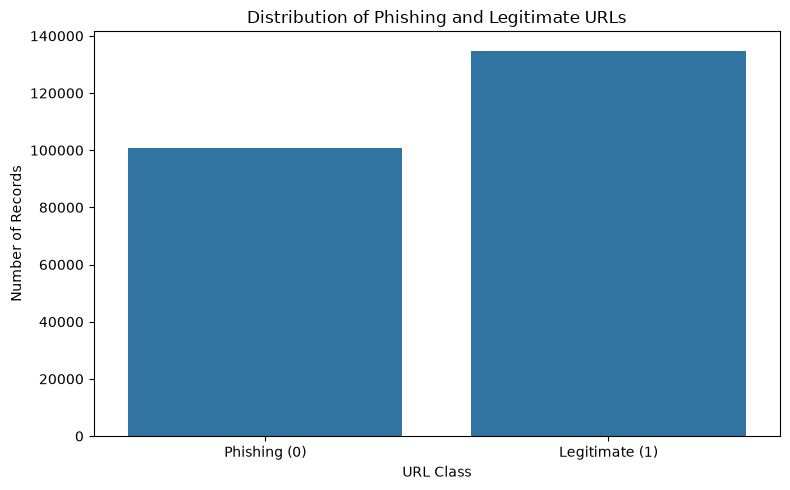

In [5]:
# Visualizing target class distribution

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x=target_column
)

ax.set_title("Distribution of Phishing and Legitimate URLs")
ax.set_xlabel("URL Class")
ax.set_ylabel("Number of Records")

ax.set_xticklabels(["Phishing (0)", "Legitimate (1)"])

plt.tight_layout()
plt.show()

## 5. Descriptive Statistics of Numerical Features

Descriptive statistics provide a statistical summary of the numerical predictive features.

The analysis includes:

- Count
- Mean
- Standard deviation
- Minimum
- First quartile (25%)
- Median (50%)
- Third quartile (75%)
- Maximum

These statistics help identify the typical range of feature values and reveal features with large differences in scale or unusually large observations.

In [6]:
# Descriptive statistics for numerical predictive features

descriptive_statistics = df[numerical_features].describe().T

descriptive_statistics["median"] = df[numerical_features].median()
descriptive_statistics["skewness"] = df[numerical_features].skew()

display(descriptive_statistics)

,count,mean,std,min,25%,50%,75%,max,median,skewness
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6.097000e+03,27.000000,53.321737
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,1.100000e+02,20.000000,2.513397
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,1.000000e+00,0.000000,19.146593
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,1.000000e+02,100.000000,-0.989903
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000e+00,1.000000,-1.128591
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,5.229071e-01,0.079963,0.073090
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,9.082366e-02,0.057970,-1.064291
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,1.300000e+01,3.000000,1.663518
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,1.000000e+01,1.000000,1.809400
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,1.000000e+00,0.000000,21.981435


### Interpretation of Descriptive Statistics

The descriptive statistics show that the numerical URL and webpage features have different value ranges.

Several features are count-based measurements, such as numbers of digits, dots, scripts, images, links, and special characters.

The difference between minimum, median, mean, and maximum values indicates that some features have highly asymmetric distributions.

The skewness values will be examined separately to identify features that may require special consideration during feature engineering or model development.

In [7]:
# Analyzing feature skewness

skewness_table = pd.DataFrame({
    "Feature": numerical_features,
    "Skewness": [
        df[column].skew()
        for column in numerical_features
    ]
})

skewness_table["Absolute Skewness"] = (
    skewness_table["Skewness"].abs()
)

skewness_table = skewness_table.sort_values(
    "Absolute Skewness",
    ascending=False
)

display(skewness_table.head(15))

,Feature,Skewness,Absolute Skewness
45,NoOfCSS,464.404031,464.404031
10,NoOfObfuscatedChar,204.684335,204.684335
46,NoOfJS,140.435761,140.435761
16,NoOfEqualsInURL,114.985479,114.985479
48,NoOfEmptyRef,106.826225,106.826225
18,NoOfAmpersandInURL,106.717256,106.717256
34,NoOfiFrame,97.677347,97.677347
14,NoOfDegitsInURL,94.877574,94.877574
33,NoOfPopup,84.952694,84.952694
49,NoOfExternalRef,65.900247,65.900247


### Interpretation of Skewness Analysis

The skewness analysis identifies numerical features whose distributions are strongly asymmetric.

A skewness value close to zero indicates a more symmetric distribution, while a large positive or negative value indicates increasing asymmetry.

The dataset contains several highly right-skewed count-based URL and webpage features. This means that most observations have relatively small values, while a smaller number of observations have unusually large values.

For example, `NoOfCSS` shows very high positive skewness. Similar behavior may be observed in other count-based features such as JavaScript, digits, special characters, links, or empty references.

Highly skewed features are not automatically removed because their extreme values may contain useful information for distinguishing phishing URLs from legitimate URLs.

The skewness results will therefore be considered during feature engineering, feature selection, and model development rather than removing features solely because they are skewed.

## 6. Distribution of Important Numerical Features

To understand the behavior of individual URL and webpage characteristics, several representative numerical features will be visualized.

The selected features represent different aspects of URL and webpage structure, including:

- URL length
- Number of digits in the URL
- Number of special characters in the URL
- Number of links
- Number of JavaScript elements
- Number of CSS elements

Since the dataset contains a large number of records, a representative random sample will be used for visualization. This improves plotting speed while preserving the overall distribution patterns of the dataset.

These visualizations will help identify skewness, concentration of values, spread, and potential extreme observations.

In [8]:
# Selecting representative features for distribution analysis

important_distribution_features = [
    "URLLength",
    "NoOfDigitsInURL",
    "NoOfSpecialCharsInURL",
    "NoOfLinks",
    "NoOfJS",
    "NoOfCSS"
]

# Keep only features that are available in the dataset
important_distribution_features = [
    feature
    for feature in important_distribution_features
    if feature in df.columns
]

print("IMPORTANT FEATURES SELECTED FOR DISTRIBUTION ANALYSIS")
print("=" * 60)

for i, feature in enumerate(important_distribution_features, start=1):
    print(f"{i}. {feature}")

print("\nTotal selected features:", len(important_distribution_features))

IMPORTANT FEATURES SELECTED FOR DISTRIBUTION ANALYSIS
1. URLLength
2. NoOfJS
3. NoOfCSS

Total selected features: 3


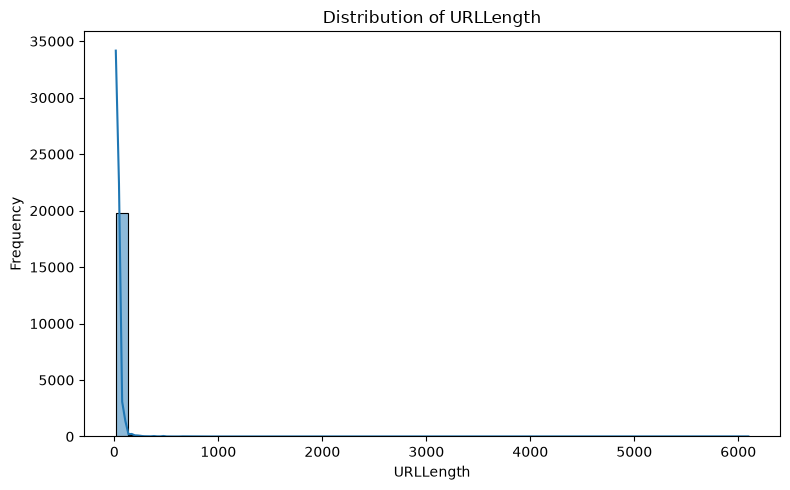

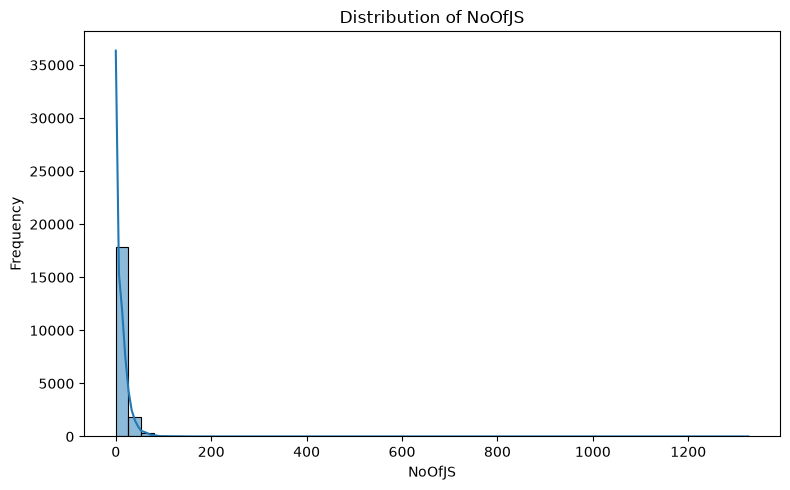

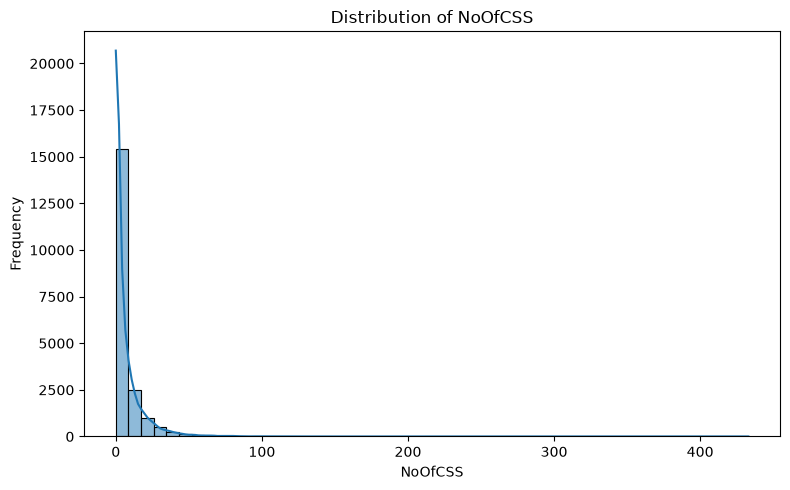

In [9]:
# Plotting distributions of important numerical features

# Take a representative sample for faster visualization
eda_sample = df.sample(
    n=min(20000, len(df)),
    random_state=42
)

for feature in important_distribution_features:
    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=eda_sample,
        x=feature,
        bins=50,
        kde=True
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

### Interpretation of Important Feature Distributions

The distribution plots provide an initial visual understanding of several important URL and webpage characteristics.

The following patterns can be observed from the distributions:

- `URLLength` shows variation in the length of URLs, with some URLs being considerably longer than the majority.
- `NoOfDigitsInURL` shows that most URLs contain relatively few digits, while a smaller number contain substantially more digits.
- `NoOfSpecialCharsInURL` indicates variation in the number of special characters used within URLs.
- `NoOfLinks` shows that webpages can contain very different numbers of links.
- `NoOfJS` and `NoOfCSS` show variation in the number of JavaScript and CSS elements associated with webpages.

Several of these distributions are positively skewed, which is consistent with the skewness analysis performed earlier.

These distributions suggest that URL structure and webpage characteristics vary considerably across the dataset. Such variation can provide useful information for distinguishing phishing URLs from legitimate URLs.

The next analysis will compare these feature distributions directly between the phishing and legitimate classes.

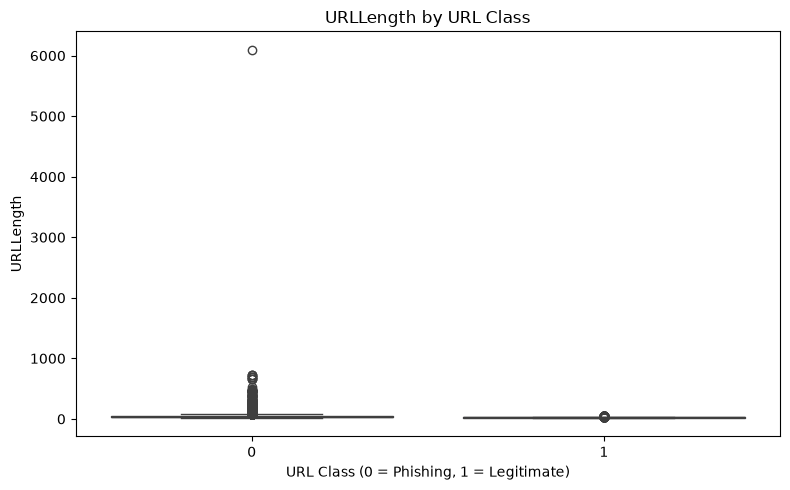

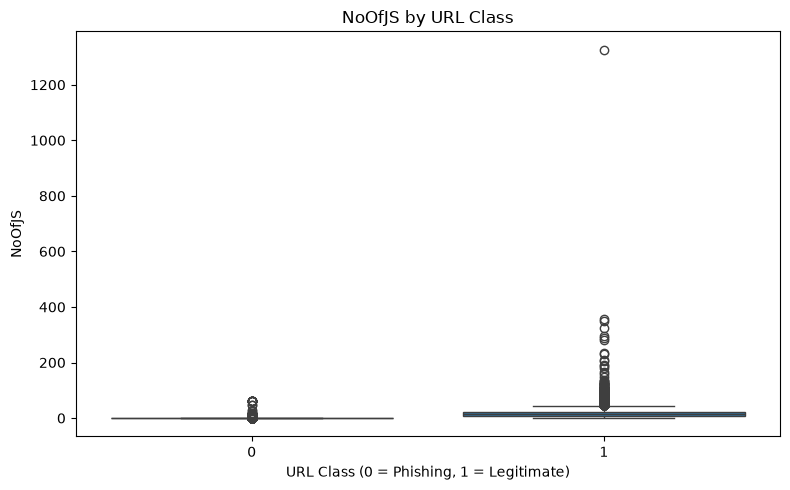

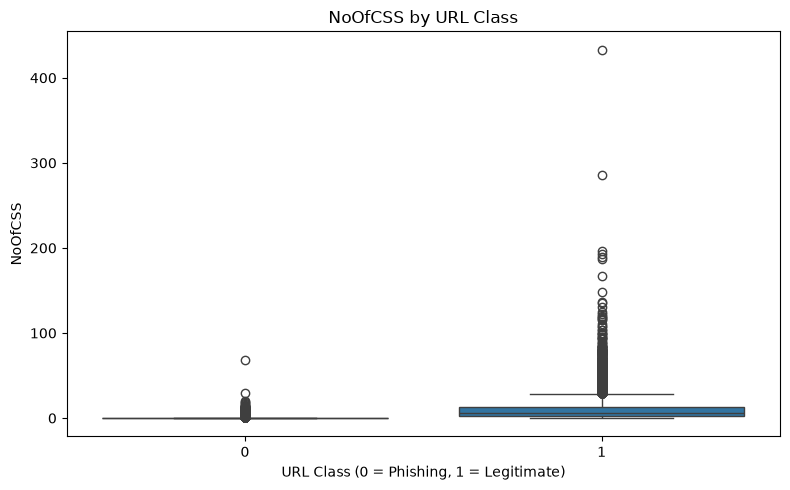

In [10]:
# Comparing important features between phishing and legitimate URLs

comparison_sample = df.sample(
    n=min(20000, len(df)),
    random_state=42
)

for feature in important_distribution_features:
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=comparison_sample,
        x=target_column,
        y=feature
    )

    plt.title(f"{feature} by URL Class")
    plt.xlabel("URL Class (0 = Phishing, 1 = Legitimate)")
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()

### Interpretation of Feature Distributions by URL Class

The boxplots compare the distributions of important URL and webpage features between the two target classes: phishing (`0`) and legitimate (`1`).

The comparison shows that the central tendency and spread of several features can differ between the two classes. Differences in the median, interquartile range, and distribution of observations indicate that URL and webpage characteristics may provide useful information for classification.

The plots also show considerable overlap between the classes for some features. This indicates that no single feature is sufficient to reliably distinguish all phishing URLs from legitimate URLs.

The presence of extreme observations is consistent with the earlier skewness and outlier analysis. These observations will not be removed automatically because they may represent meaningful URL or webpage characteristics.

Overall, the class-based distributions support the use of multiple features together for phishing URL classification. The predictive contribution of individual features will be investigated more systematically during feature selection.

## 8. Correlation Analysis

Correlation analysis is performed to understand the relationships between the numerical predictive features and the target variable.

The Pearson correlation coefficient ranges from -1 to +1:

- A value close to +1 indicates a strong positive linear relationship.
- A value close to -1 indicates a strong negative linear relationship.
- A value close to 0 indicates a weak linear relationship.

In this project, correlation analysis is used as an exploratory technique to identify features that may have a relationship with the phishing/legitimate target and to identify groups of features that may contain similar information.

Correlation does not prove causation, and a low linear correlation does not necessarily mean that a feature has no predictive value. Non-linear relationships may still be useful to machine learning models.

The correlation results will therefore be used as supporting information for later feature-selection and model-building stages rather than as the sole basis for removing features.

In [11]:
# Correlation of numerical features with the target variable

numerical_features_for_corr = [
    column
    for column in df.select_dtypes(include=["int64", "float64"]).columns
    if column != target_column
]

correlation_with_target = (
    df[numerical_features_for_corr + [target_column]]
    .corr()[target_column]
    .drop(target_column)
    .sort_values(key=abs, ascending=False)
)

correlation_table = pd.DataFrame({
    "Feature": correlation_with_target.index,
    "Correlation with Label": correlation_with_target.values
})

correlation_table["Absolute Correlation"] = (
    correlation_table["Correlation with Label"].abs()
)

print("TOP FEATURES CORRELATED WITH THE TARGET")
print("=" * 70)

display(correlation_table.head(20))

TOP FEATURES CORRELATED WITH THE TARGET


,Feature,Correlation with Label,Absolute Correlation
0,URLSimilarityIndex,0.860358,0.860358
1,HasSocialNet,0.784255,0.784255
2,HasCopyrightInfo,0.743358,0.743358
3,HasDescription,0.690232,0.690232
4,IsHTTPS,0.609132,0.609132
5,DomainTitleMatchScore,0.584905,0.584905
6,HasSubmitButton,0.578561,0.578561
7,IsResponsive,0.548608,0.548608
8,URLTitleMatchScore,0.539419,0.539419
9,SpacialCharRatioInURL,-0.533537,0.533537


### Interpretation of Feature-Target Correlation

The correlation analysis provides an initial view of the linear relationship between the numerical predictive features and the target variable.

Features with larger absolute correlation values show a stronger linear association with the target, while features with values closer to zero show weaker linear associations.

A negative correlation indicates that larger values of the feature tend to be associated with the phishing class (`0`), while a positive correlation indicates that larger values tend to be associated with the legitimate class (`1`).

However, correlation should not be interpreted as proof of causation or as the final measure of feature importance. A feature with a low linear correlation may still provide useful information through non-linear relationships or interactions with other features.

The correlation results will therefore be used as exploratory evidence. Final feature importance will be determined later using appropriate feature-selection and model-based techniques.

The next step is to visualize the relationships among the most target-related numerical features using a correlation heatmap.

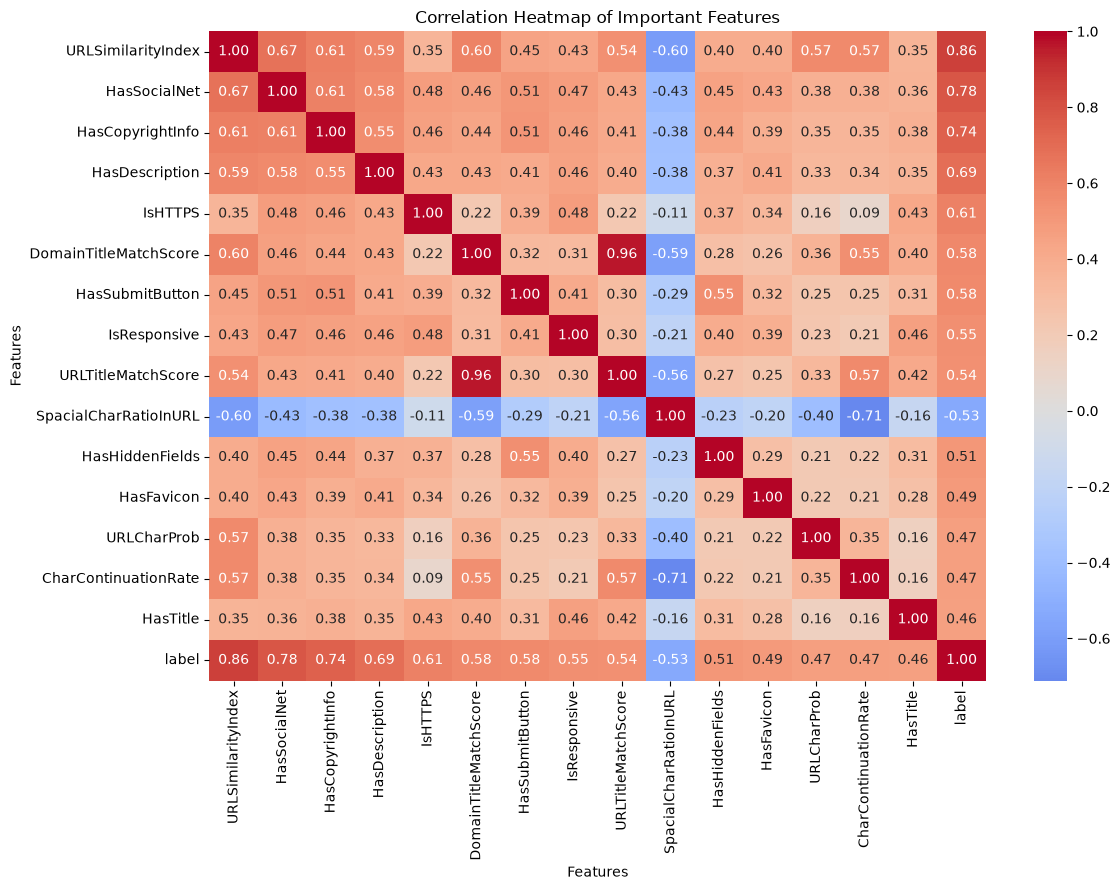

In [12]:
# Creating a correlation heatmap for the most target-related features

top_correlation_features = correlation_table.head(15)["Feature"].tolist()

heatmap_features = top_correlation_features + [target_column]

correlation_matrix = df[heatmap_features].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Important Features")
plt.xlabel("Features")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

### Interpretation of Correlation Heatmap

The correlation heatmap provides a visual representation of the relationships among the selected numerical features and the target variable.

The target variable shows relatively strong correlations with several features. In particular, `URLSimilarityIndex`, `HasSocialNet`, `HasCopyrightInfo`, `HasDescription`, and `IsHTTPS` show comparatively stronger associations with the target than many other features.

`SpecialCharRatioInURL` has a negative correlation with the target, indicating that higher values of this feature tend to be associated with the phishing class (`0`) relative to the legitimate class (`1`).

The heatmap also reveals relationships between some predictor variables. For example, `DomainTitleMatchScore` and `URLTitleMatchScore` show a strong positive correlation, indicating that these features may contain partially overlapping information.

Similarly, several URL-character-related features show moderate relationships with each other.

These correlations are useful for understanding the structure of the dataset, but correlation alone will not be used to determine the final feature set. Model-based feature importance and feature-selection techniques will be applied later.

Overall, the heatmap confirms that multiple URL and webpage characteristics contain potentially useful information for phishing URL classification.

## 9. EDA Summary and Key Observations

The exploratory data analysis provides several important observations about the PhiUSIIL phishing URL dataset.

### Dataset Structure
- The dataset contains 235,795 records and 56 columns.
- There are 50 numerical predictive features.
- The dataset also contains URL, domain, TLD, and title-related text information.
- `label` is the target variable, where `0` represents phishing and `1` represents legitimate URLs.

### Data Quality
- No missing values were identified in the dataset.
- No completely duplicated records were found.
- URL-level repetition is limited, with only a small proportion of records sharing repeated URLs.
- No constant numerical predictive features were identified.

### Distribution Analysis
- Several numerical URL and webpage features are strongly right-skewed.
- Count-based features such as CSS, JavaScript, digits, links, and special-character-related measurements can contain extreme values.
- These extreme observations are retained because they may contain useful information for classification.

### Class-Based Analysis
- The distributions of several numerical features differ between phishing and legitimate URLs.
- However, substantial overlap exists between the two classes for some features.
- This indicates that a combination of multiple features is more appropriate than relying on a single variable.

### Correlation Analysis
- Several features show relatively strong linear associations with the target.
- `URLSimilarityIndex`, `HasSocialNet`, `HasCopyrightInfo`, `HasDescription`, and `IsHTTPS` are among the features with comparatively stronger target correlations.
- Some predictor variables are also strongly correlated with each other, indicating possible redundancy.

### Overall EDA Conclusion

The exploratory analysis confirms that the dataset contains diverse URL and webpage characteristics that can be used for phishing classification.

The findings from EDA will be used to guide the next stages of the project, particularly feature engineering and feature selection. Features will not be removed solely because of skewness or low correlation, since machine learning models can capture non-linear relationships and interactions between variables.

In [ ]:
# Final EDA verification

# Recalculate constant predictive features
constant_features_final = [
    column
    for column in numerical_features_for_corr
    if df[column].nunique() <= 1
]

print("FINAL EDA VERIFICATION")
print("=" * 70)

print("Dataset records:", len(df))
print("Total columns:", len(df.columns))
print("Numerical predictive features:", len(numerical_features_for_corr))
print("Text/Categorical columns:", len(text_columns))

print("\nTarget variable:", target_column)

print("\nTarget distribution:")
print(df[target_column].value_counts().sort_index())

print("\nMissing values:", df.isnull().sum().sum())
print("Completely duplicated rows:", df.duplicated().sum())

print("\nUnique URLs:", df["URL"].nunique())
print("Repeated URL records:", len(df) - df["URL"].nunique())

print(
    "\nConstant predictive features:",
    len(constant_features_final)
)

print("\nEDA components completed:")
print("- Descriptive statistics")
print("- Missing-value analysis")
print("- Duplicate analysis")
print("- Skewness analysis")
print("- Feature distributions")
print("- Class-based feature comparison")
print("- Feature-target correlation")
print("- Correlation heatmap")
print("- EDA observations")

print("\nExploratory Data Analysis completed successfully.")